---
title: "Week 8B: Street Network Analysis with NetworkX"
format:
  html:
    toc: true
    toc-depth: 3
    number-sections: true
    code-fold: false
    embed-resources: true
    theme: cosmo
execute:
  enabled: false
---

## Street Network Analysis using NetworkX

This lab keeps the step-by-step graph demonstrations, then builds a sidewalk network from line data. We will inspect nodes and edges, use weights, find shortest paths, export a route, and locate the nearest node to a point.

The sidewalk example is an **undirected, distance-based walking model**. It does not model live traffic or driving restrictions. Run the cells in order; restarting the kernel and running all cells is a useful reproducibility check.

References: [NetworkX tutorial](https://networkx.org/documentation/stable/tutorial.html) and [shortest-path algorithms](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html).

In [1]:
import networkx as nx
print(nx.__version__)

3.6.1


### Setup

Use a kernel with NetworkX, GeoPandas, NumPy, and Matplotlib. The version shown above is the version used by this notebook; a terminal can use a different environment. The shapefile reader below uses GeoPandas, so there is no need to import GDAL/OGR directly.

In [2]:
# Run only if packages are missing, then restart the kernel:
# %pip install networkx geopandas numpy matplotlib

We begin with small graphs to learn the API. Later, sidewalk line endpoints become nodes, line features become edges, and line lengths become routing costs. Keep graph connectivity and measurement units in mind when interpreting a route.

In [3]:
from pathlib import Path

import geopandas as gpd
import numpy as np
from matplotlib import pyplot as plt
from shapely.geometry import LineString, MultiLineString, Point
from IPython.display import display

plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 11})

### Create an empty graph

`nx.Graph()` is undirected: travel can occur in either direction. A directed graph uses `nx.DiGraph()`.

In [4]:
G = nx.Graph()

**Nodes**

The graph `G` can be grown in several ways. NetworkX includes many graph generator functions and facilities to read and write graphs in many formats. To get started though we’ll look at simple manipulations. You can add one node at a time,


In [5]:
G.add_node(1)

or add nodes from any iterable container, such as a list


In [6]:
G.add_nodes_from([2, 3])

Add nodes with attributes. Attributes store information about an object; they do not change connectivity.

In [7]:
G.add_nodes_from([
    (4, {"color": "red"}),
    (5, {"color": "green"}),
])

We can draw the graph, 

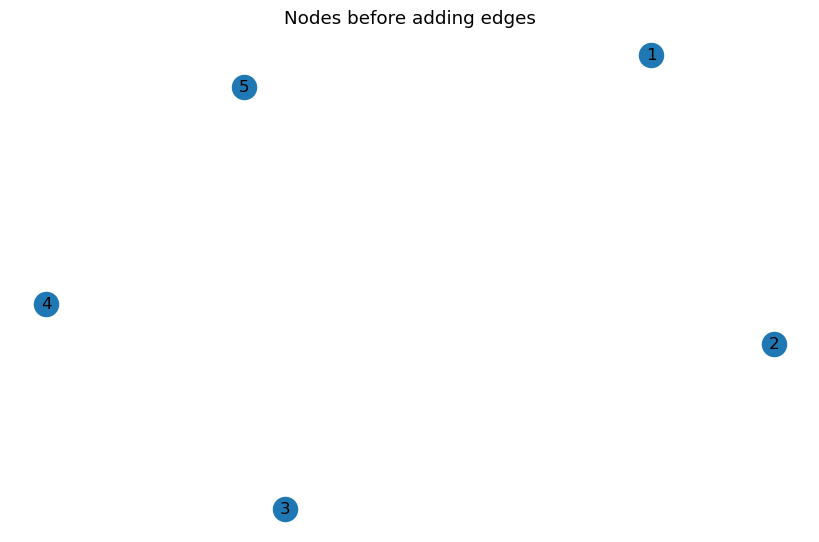

In [8]:
nx.draw(G, pos=nx.spring_layout(G, seed=8), with_labels=True)
plt.title("Nodes before adding edges")
plt.show()

Print all the nodes of a graph

In [9]:
G.nodes

NodeView((1, 2, 3, 4, 5))

To get the node data along with the nodes:

In [10]:
G.nodes[1], G.nodes[4]

({}, {'color': 'red'})

In [11]:
G.has_node(1)

True

### Edges

An edge connects two nodes. Adding an edge also creates its endpoints if they are not already in the graph.

In [12]:
G.add_edge(1, 2)
e = (2, 3)
G.add_edge(*e)  # Unpack the tuple into two node arguments.

In [13]:
G.add_edges_from([(1, 2), (1, 3)])

In [14]:
list(G.edges)  # Adding the same edge again does not duplicate it in a Graph.

[(1, 2), (1, 3), (2, 3)]

Check if the graph has the edge

In [15]:
G.has_edge(*(1, 2))  # Tuple unpacking form.

True

In [16]:
G.has_edge(1, 2)  # Equivalent explicit-argument form.

True

In [17]:
G.number_of_nodes()

5

In [18]:
G.number_of_edges()

3

### Examining elements of a graph

- `G.nodes`: node IDs and attributes.
- `G.edges`: connections and edge attributes.
- `G.adj[node]`: adjacent nodes and their edge data.
- `G.degree[node]`: number of incident edges in this undirected graph.

These are views of the graph. Convert a view to `list(...)` when you want a concrete list to inspect. The following cells show each view separately.

In [19]:
list(G.nodes)

[1, 2, 3, 4, 5]

In [20]:
list(G.edges)


[(1, 2), (1, 3), (2, 3)]

Find the nodes adjacent to node 1. **Predict their IDs before running the cell.**

In [21]:
list(G.adj[1])  # or list(G.neighbors(1))

[2, 3]

In [22]:
G.degree

DegreeView({1: 2, 2: 2, 3: 2, 4: 0, 5: 0})

In [23]:
# the number of edges incident to 1
G.degree[1]

2

### Edge attributes

Edges can store distances, travel times, or other information. Attribute names are your choice. Here we practice assigning `weight` and `color`; not every edge has a weight yet. A weighted shortest-path calculation treats a missing weight as 1, so later routing examples assign a cost to every edge.

In [24]:
G.add_edge(1, 2, weight=4.7 )
G.add_edges_from([(3, 4), (4, 5)], color='red')
G.add_edges_from([(1, 2, {'color': 'blue'}), (2, 3, {'weight': 8})])
G[1][2]['weight'] = 4.7
G.edges[3, 4]['weight'] = 4.2

In [25]:
list(G.edges)

[(1, 2), (1, 3), (2, 3), (3, 4), (4, 5)]

In [26]:
G.edges[3, 4]

{'color': 'red', 'weight': 4.2}

### Drawing example graphs

These graph generators help demonstrate layouts. Each example starts from a new graph so it does not accidentally modify a previous example.

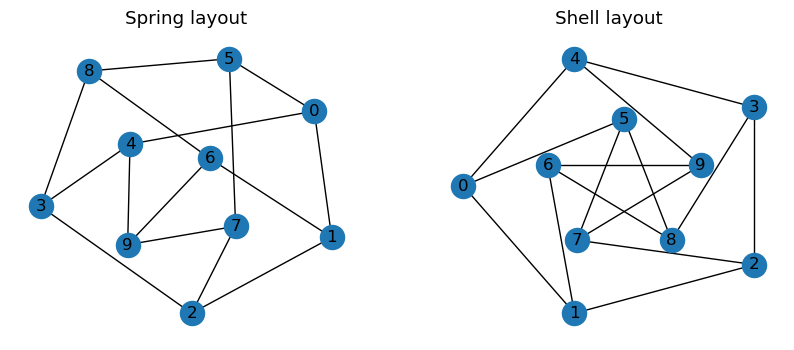

In [27]:
G = nx.petersen_graph()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
nx.draw(G, pos=nx.spring_layout(G, seed=8), with_labels=True, ax=axes[0])
nx.draw_shell(G, nlist=[range(5, 10), range(5)], with_labels=True, ax=axes[1])
axes[0].set_title("Spring layout")
axes[1].set_title("Shell layout")
plt.show()

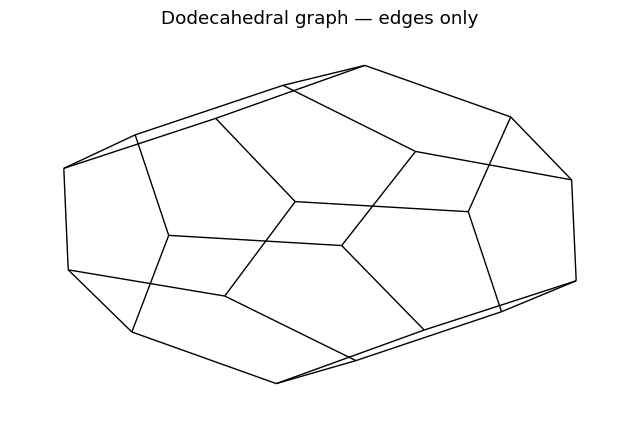

In [28]:
G = nx.dodecahedral_graph()
fig, ax = plt.subplots()
nx.draw_networkx_edges(G, pos=nx.spring_layout(G, seed=8), ax=ax)
ax.set_title("Dodecahedral graph — edges only")
ax.set_axis_off()
plt.show()

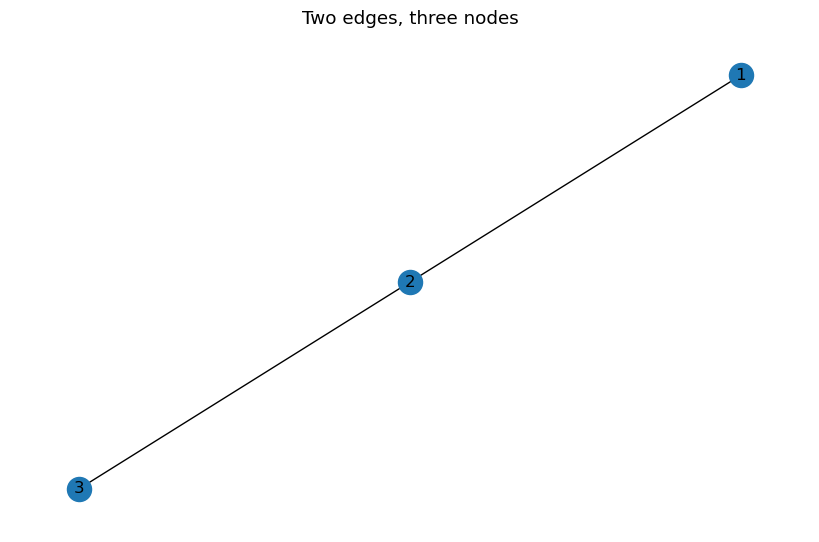

In [29]:
# A separate minimal graph for comparison.
G = nx.Graph()
G.add_edge(1, 2)
G.add_edge(2, 3)
nx.draw(G, pos=nx.spring_layout(G, seed=8), with_labels=True)
plt.title("Two edges, three nodes")
plt.show()

In [30]:
# Optional Python detail: node IDs can be any hashable object.
import math
G_objects = nx.Graph()
G_objects.add_edge("y", "x", function=math.cos)
G_objects.add_node(math.cos)
print("Number of nodes:", G_objects.number_of_nodes())
print("Edge attribute:", G_objects.edges["y", "x"]["function"].__name__)

Number of nodes: 3
Edge attribute: cos


In [31]:
G = nx.Graph()
G.add_edges_from([(1, 2), (2, 3), (1, 4), (4, 2)])
G.add_weighted_edges_from([
    ("a", "b", 5.0), ("b", "c", 3.0), ("a", "c", 1.0), ("c", "d", 7.3)
])
print("Components:", nx.number_connected_components(G))

Components: 2


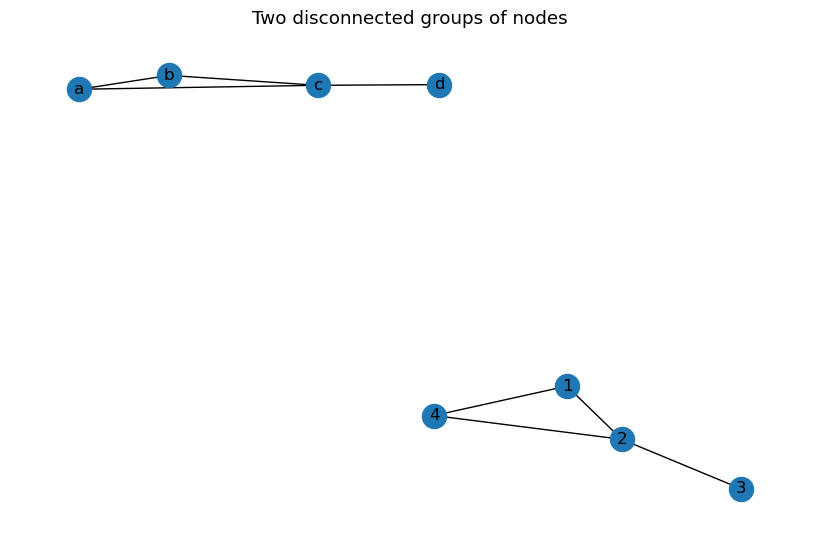

In [32]:
nx.draw(G, pos=nx.spring_layout(G, seed=8), with_labels=True)
plt.title("Two disconnected groups of nodes")
plt.show()

In [33]:
G = nx.Graph()
e = [('a', 'b', 0.3), ('b', 'c', 0.9), ('a', 'c', 0.5), ('c', 'd', 1.2)]
G.add_weighted_edges_from(e)

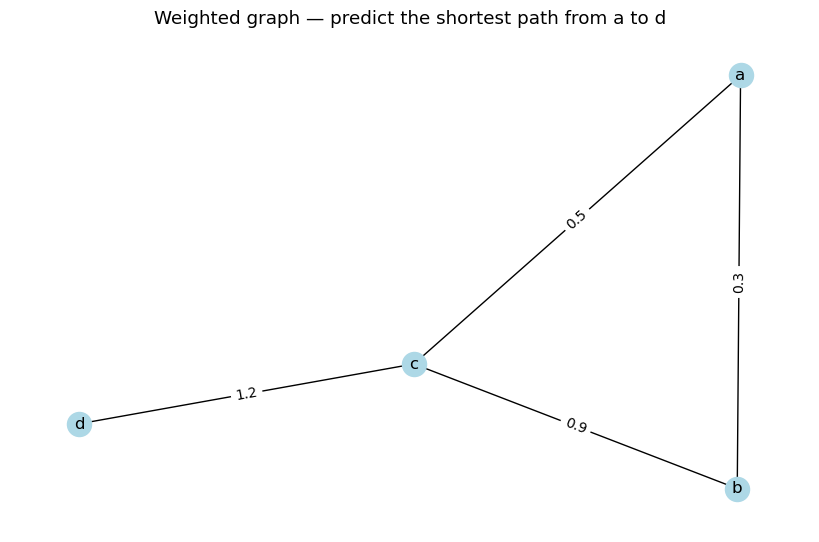

In [34]:
pos = nx.spring_layout(G, seed=8)
nx.draw(G, pos=pos, with_labels=True, node_color="lightblue")
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))
plt.title("Weighted graph — predict the shortest path from a to d")
plt.show()

In [35]:
toy_path = nx.dijkstra_path(G, "a", "d", weight="weight")
print("Shortest path:", toy_path)
print("Total weight:", nx.path_weight(G, toy_path, weight="weight"))

Shortest path: ['a', 'c', 'd']
Total weight: 1.7


### Conduct network analysis on the sidewalk data

The next cells retain the helper-function workflow: convert line geometry to edges, read the file, inspect components, and build a routing graph. Their implementations use GeoPandas and Shapely instead of the removed NetworkX shapefile API.

**Assumptions:** travel is bidirectional; only exactly matching line endpoints connect. Crossings without shared endpoints, gaps, missing crossings, and grade separation require additional topology work for a real routing system.

#### Helper 1: Convert line geometry to graph edges

`edges_from_line()` yields endpoint pairs and edge attributes. By default, intermediate vertices preserve the line's shape but do not become graph nodes. `simplify=False` instead splits a line at every coordinate; those coordinates are not automatically meaningful street intersections.

In [36]:
def edges_from_line(geom, attrs, simplify=True, geom_attrs=True):
    """Yield (start, end, attributes) from Shapely line geometry."""
    if isinstance(geom, MultiLineString):
        for part in geom.geoms:
            yield from edges_from_line(part, attrs, simplify, geom_attrs)
    elif isinstance(geom, LineString):
        coordinates = list(geom.coords)
        parts = [geom] if simplify else [
            LineString([u, v]) for u, v in zip(coordinates[:-1], coordinates[1:])
        ]
        for line in parts:
            if line.length <= 0:
                continue
            edge_attrs = attrs.copy()
            edge_attrs["length"] = line.length
            if geom_attrs:
                edge_attrs["geometry"] = line
            yield tuple(line.coords[0][:2]), tuple(line.coords[-1][:2]), edge_attrs
    else:
        raise TypeError("Expected a LineString or MultiLineString.")

In [37]:
def read_shp(path, simplify=True, geom_attrs=True, strict=True):
    """Read line data into a MultiGraph, retaining parallel sidewalk segments.

    This is our own helper, not a NetworkX built-in. Lengths use source CRS units.
    """
    lines = gpd.read_file(path).explode(index_parts=False).reset_index(drop=True)
    if lines.crs is None or not lines.crs.is_projected:
        raise ValueError("Use a known projected CRS before measuring line lengths.")
    net = nx.MultiGraph(crs=lines.crs)
    skipped = 0
    for segment_id, row in lines.iterrows():
        geom = row.geometry
        if geom is None or geom.is_empty or not geom.is_valid or geom.geom_type != "LineString":
            if strict:
                raise ValueError(f"Invalid or unsupported line at row {segment_id}.")
            skipped += 1
            continue
        attrs = {"segment_id": segment_id, "objectid": row.get("objectid", segment_id)}
        for u, v, data in edges_from_line(geom, attrs, simplify, geom_attrs):
            net.add_edge(u, v, **data)
    print(f"Skipped invalid features: {skipped}")
    return net

In [38]:
def connected_component_subgraphs(G):
    """Yield a view of each connected component of an undirected graph."""
    for nodes in nx.connected_components(G):
        yield G.subgraph(nodes)


def getNetworkGraph(segments, segmentlengths):
    """Build the graph and retain the component with the most nodes."""
    full_graph = read_shp(segments)
    if full_graph.number_of_nodes() == 0:
        raise ValueError("No routable line endpoints were found.")
    graph = max(connected_component_subgraphs(full_graph), key=len).copy()
    for u, v, key, data in graph.edges(keys=True, data=True):
        data["length"] = segmentlengths[data["segment_id"]]
    print(f"Components: {nx.number_connected_components(full_graph):,}")
    print(f"Selected {len(graph):,} of {len(full_graph):,} nodes; {graph.number_of_edges():,} edges")
    return graph


def getSegmentInfo(segments):
    """Read endpoints and native-unit lengths, keyed by unique line-part ID."""
    lines = gpd.read_file(segments).explode(index_parts=False).reset_index(drop=True)
    endpoints, segmentlengths = {}, {}
    for segment_id, geom in lines.geometry.items():
        if geom is None or geom.is_empty or geom.geom_type != "LineString":
            raise ValueError(f"Unsupported geometry at row {segment_id}.")
        endpoints[segment_id] = (tuple(geom.coords[0][:2]), tuple(geom.coords[-1][:2]))
        segmentlengths[segment_id] = geom.length
    print(f"Line parts: {len(endpoints):,}")
    return endpoints, segmentlengths


def buildNetwork(segments):
    endpoints, lengths = getSegmentInfo(segments)
    graph = getNetworkGraph(segments, lengths)
    return endpoints, lengths, graph

Build the graph from the supplied [sidewalk ZIP](data/sidewalk.zip). GeoPandas reads the ZIP directly, so you do not need to extract it.

The dataset uses EPSG:2272, whose coordinates and line lengths are in **US survey feet**. We retain the original coordinates so the endpoint examples below remain meaningful, and convert reported distances to meters explicitly.

In [39]:
lab_dir = Path.cwd()
if not (lab_dir / "data/sidewalk.zip").exists():
    lab_dir = lab_dir / "labs/week-8-network-analysis"
sidewalk_path = lab_dir / "data/sidewalk.zip"
if not sidewalk_path.exists():
    raise FileNotFoundError("The lab's data/sidewalk.zip file is required.")
streetMap = f"zip://{sidewalk_path.resolve()}"
endpoints, lengths, graph = buildNetwork(streetMap)
crs = graph.graph["crs"]
unit_name = crs.axis_info[0].unit_name
meters_per_unit = crs.axis_info[0].unit_conversion_factor
print("CRS:", crs, "| distance unit:", unit_name)

Line parts: 130,966


Skipped invalid features: 0


Components: 989
Selected 88,516 of 91,261 nodes; 129,104 edges
CRS: EPSG:2272 | distance unit: US survey foot


**Checkpoint:** the largest connected component is selected with `max(..., key=len)`, not by taking the first component. This prevents routes between disconnected groups, but does not fix the underlying topology.

If the file cannot be read, check that you are in the lab or course folder and that `data/sidewalk.zip` is present. Select an environment with GeoPandas; the old direct `osgeo.ogr` dependency is no longer needed.

Use two endpoints from the original sidewalk example as the origin and destination. These are projected `(x, y)` coordinates, not longitude and latitude. Check membership before routing, and raise a clear error instead of leaving stale variables from an earlier run.

In [40]:
s1_point = (2674629.019778946, 233887.42317315526)
s2_point = (2676819.994840707, 233998.8937345071)
if not (graph.has_node(s1_point) and graph.has_node(s2_point)):
    raise ValueError("An example endpoint is absent from the selected component.")
dist, path = nx.single_source_dijkstra(graph, s1_point, target=s2_point, weight="length")

In [41]:
print(f"Distance: {dist:,.1f} {unit_name} = {dist * meters_per_unit:,.1f} meters")
print("First route nodes:", path[:5])

Distance: 2,239.2 US survey foot = 682.5 meters
First route nodes: [(2674629.019778946, 233887.42317315526), (2675063.484593347, 233895.2384052628), (2675115.2077349196, 233892.43677666123), (2675131.3505460056, 233892.1815988601), (2675157.64553571, 233891.76624855347)]


#### Recover the shortest route's source segments

A MultiGraph can contain parallel edges. Select the minimum-length edge between each successive node pair, matching the cost used by Dijkstra's algorithm. Retaining source IDs makes the route traceable.

In [42]:
def route_edge_data(graph, path):
    """Return the minimum-length edge data for each consecutive node pair."""
    selected = []
    for u, v in zip(path[:-1], path[1:]):
        choices = graph[u][v]
        key = min(choices, key=lambda k: choices[k]["length"])
        selected.append(choices[key])
    return selected

selected_edges = route_edge_data(graph, path)
subpath = [edge["objectid"] for edge in selected_edges]
print("Source object IDs:", subpath)

Source object IDs: [67, 101354, 153614, 136348, 99194, 119948, 83281, 112093, 158108, 91137, 180777, 175219, 80366, 179855, 155287, 99997, 115588, 75881, 177392, 125590, 163167]


In [43]:
list(graph.nodes)[:11]  # A small preview; avoid looping through the entire graph.

[(2674629.019778946, 233887.42317315526),
 (2675063.484593347, 233895.2384052628),
 (2677370.9139951007, 234099.03786372015),
 (2677331.098267104, 234139.85190359864),
 (2676819.994840707, 233998.8937345071),
 (2676874.8400247567, 234004.04994090827),
 (2677398.8984584543, 234090.96045311925),
 (2677452.6642256537, 234098.92121608992),
 (2677418.0230016173, 234179.81781638178),
 (2677382.3291674173, 234191.45753613432),
 (2676893.9161705, 233916.11122627818)]

In [44]:
# Try a second pair from the original demonstration.
s1_point = (2675063.484593347, 233895.2384052628)
s2_point = (2688743.6504137763, 232314.04444539145)

In [45]:
graph.has_node(s1_point)

True

In [46]:
graph.has_node(s2_point)

True

In [47]:
if not (graph.has_node(s1_point) and graph.has_node(s2_point)):
    raise ValueError("An example endpoint is absent from the selected component.")
dist, path = nx.single_source_dijkstra(graph, s1_point, target=s2_point, weight="length")

In [48]:
print(f"Distance: {dist:,.1f} {unit_name} = {dist * meters_per_unit:,.1f} meters")

Distance: 16,415.9 US survey foot = 5,003.6 meters


In [49]:
print(f"Route nodes: {len(path)}")
path[:10]

Route nodes: 144


[(2675063.484593347, 233895.2384052628),
 (2675115.2077349196, 233892.43677666123),
 (2675131.3505460056, 233892.1815988601),
 (2675157.64553571, 233891.76624855347),
 (2675194.6822983907, 233894.80562187612),
 (2675558.573598633, 233899.59502712416),
 (2675613.0183556173, 233905.90717337467),
 (2675630.2018974577, 233911.72542009607),
 (2675651.2510666423, 233903.49926487225),
 (2675728.5513929822, 233904.42103680802)]

### Create a shapefile from the route

Retain the original source-line geometry. Drawing straight lines between endpoint nodes would remove the curves in the sidewalks and misrepresent the route.

We first create and inspect a route GeoDataFrame, then provide an optional export. The rows are ordered along the route; individual line-coordinate directions may differ because this is an undirected graph.

In [50]:
selected_edges = route_edge_data(graph, path)
route_gdf = gpd.GeoDataFrame(
    [{"order": i + 1, "objectid": edge["objectid"], "length": edge["length"],
      "geometry": edge["geometry"]} for i, edge in enumerate(selected_edges)],
    crs=graph.graph["crs"],
)
assert np.isclose(route_gdf["length"].sum(), dist)
route_gdf.head()

,order,objectid,length,geometry
0,1,101354,51.798962,"LINESTRING (2675115.208 233892.437, 2675063.48..."
1,2,153614,16.144828,"LINESTRING (2675131.351 233892.182, 2675115.20..."
2,3,136348,26.298270,"LINESTRING (2675157.646 233891.766, 2675131.35..."
3,4,99194,37.161265,"LINESTRING (2675157.646 233891.766, 2675194.68..."
4,5,119948,364.351612,"LINESTRING (2675558.574 233899.595, 2675543.38..."


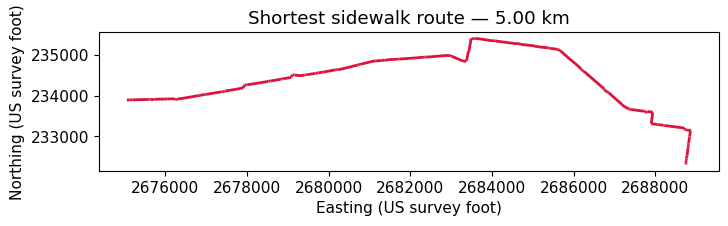

In [51]:
ax = route_gdf.plot(color="crimson", linewidth=2)
ax.set_title(f"Shortest sidewalk route — {dist * meters_per_unit / 1000:.2f} km")
ax.set_xlabel(f"Easting ({unit_name})")
ax.set_ylabel(f"Northing ({unit_name})")
ax.ticklabel_format(style="plain", useOffset=False)
plt.show()

In [52]:
# Optional: write the route as a shapefile. A new folder avoids overwriting results.
EXPORT_ROUTE = False
if EXPORT_ROUTE:
    from datetime import datetime
    export_dir = lab_dir / "outputs" / datetime.now().strftime("route-%Y%m%d-%H%M%S-%f")
    export_dir.mkdir(parents=True)
    route_gdf.to_file(export_dir / "route.shp", driver="ESRI Shapefile", index=False)
    print(f"Saved route shapefile and companion files in {export_dir}")
else:
    print("Set EXPORT_ROUTE = True to save the route shapefile.")

Set EXPORT_ROUTE = True to save the route shapefile.


#### Find the nearest node to any input point

If a location is not already a graph node, snap it to the nearest node using Euclidean distance in the projected CRS. The following cells retain each calculation step so you can inspect the arrays.

This finds the nearest **node**, not the nearest point along an edge. The snap distance is separate from the route distance.

Preview a few node coordinates before converting them into a NumPy array.

In [53]:
list(graph.nodes)[:11]

[(2674629.019778946, 233887.42317315526),
 (2675063.484593347, 233895.2384052628),
 (2677370.9139951007, 234099.03786372015),
 (2677331.098267104, 234139.85190359864),
 (2676819.994840707, 233998.8937345071),
 (2676874.8400247567, 234004.04994090827),
 (2677398.8984584543, 234090.96045311925),
 (2677452.6642256537, 234098.92121608992),
 (2677418.0230016173, 234179.81781638178),
 (2677382.3291674173, 234191.45753613432),
 (2676893.9161705, 233916.11122627818)]

Convert coordinates into an array with one row per node and two columns: x and y.

In [54]:
nodelist = list(graph.nodes)
node_array = np.asarray(nodelist, dtype=float)

In [55]:
node_array.shape

(88516, 2)

In [56]:
node_array[0,:]

array([2674629.01977895,  233887.42317316])

Specify a point in the same source CRS as the graph. It is slightly offset from an endpoint used above.

In [57]:
anypnt = (2675067.484593347, 233893.2384052628)

Calculate the x and y differences from the input point to every node. Broadcasting subtracts the same point from every row.

In [58]:
coordinate_diff = node_array - np.asarray(anypnt)

In [59]:
coordinate_diff.shape

(88516, 2)

Square the differences and sum across x and y. This gives squared Euclidean distance. Summing absolute differences instead would compute Manhattan distance and can select a different node.

In [60]:
squared_distance = np.sum(coordinate_diff ** 2, axis=1)
squared_distance.shape

(88516,)

Find the row index with the smallest squared distance. A square root is unnecessary until we want to report the actual distance.

In [61]:
index = int(squared_distance.argmin())
index

1

Use the calculated index—not a fixed index such as 1—to retrieve the nearest node.

In [62]:
nearest = nodelist[index]
nearest

(2675063.484593347, 233895.2384052628)

In [63]:
snap_distance = float(np.sqrt(squared_distance[index]))
print("Input point:", anypnt)
print("Nearest node:", nearest)
print(f"Snap distance: {snap_distance:.2f} {unit_name} ({snap_distance * meters_per_unit:.2f} m)")

Input point: (2675067.484593347, 233893.2384052628)
Nearest node: (2675063.484593347, 233895.2384052628)
Snap distance: 4.47 US survey foot (1.36 m)


### Practice and interpretation

1. Change a toy graph's edge weight and predict the new shortest route.
2. Explain why the largest connected component is used and what data it excludes.
3. Compare the source CRS units with the reported meter distance.
4. Change `anypnt`, rerun the nearest-node cells, and inspect the snap distance.
5. Explain why exporting the original sidewalk geometry is preferable to drawing endpoint-to-endpoint chords.

For real routing, inspect connectivity, crossings, access restrictions, and snapping errors before drawing conclusions.